In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# Load market index data
asx = pd.read_excel(
    r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\ASX200_Market_Data_2015_2025.xlsx",
    sheet_name="Close Prices"
)

sp500 = pd.read_excel(
    r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\SP500_2016_2025_with_start_price.xlsx"
)

sti = pd.read_excel(
    r"C:\Users\ALIENWARE\OneDrive\Desktop\26s2\ECMT3150\group project\STI_2016_2025_with_start_price.xlsx"
)

# Inspect data
print("ASX 200:")
print(asx.head())

print("\nS&P 500:")
print(sp500.head())

print("\nSTI:")
print(sti.head())

ASX 200:
        Date  ASX200_Close
0 2015-12-31   5295.899902
1 2016-01-04   5270.500000
2 2016-01-05   5184.399902
3 2016-01-06   5123.100098
4 2016-01-07   5010.299805

S&P 500:
        Date        Close
0 2015-12-31  2043.939941
1 2016-01-04  2012.660034
2 2016-01-05  2016.709961
3 2016-01-06  1990.260010
4 2016-01-07  1943.089966

STI:
        Date        Close
0 2015-12-31  2882.729980
1 2016-01-04  2835.969971
2 2016-01-05  2834.229980
3 2016-01-06  2804.270020
4 2016-01-07  2729.909912


In [3]:
# Rename price columns
asx = asx.rename(columns={
    "ASX200_Close": "Close"
})

# SP500 and STI already have Date and Close
print(asx.columns)
print(sp500.columns)
print(sti.columns)

Index(['Date', 'Close'], dtype='str')
Index(['Date', 'Close'], dtype='str')
Index(['Date', 'Close'], dtype='str')


In [4]:
# Data cleaning and inspection
markets = {
    "ASX200": asx,
    "SP500": sp500,
    "STI": sti
}

for name, df in markets.items():

    df["Date"] = pd.to_datetime(
        df["Date"], errors="coerce"
    )

    df["Close"] = pd.to_numeric(
        df["Close"], errors="coerce"
    )

    df.dropna(subset=["Date"], inplace=True)
    df.sort_values("Date", inplace=True)

    print(f"\n{name}")
    print("Missing values:")
    print(df.isna().sum())
    print("Duplicate dates:", df["Date"].duplicated().sum())
    print("Date range:", df["Date"].min(), "to", df["Date"].max())


ASX200
Missing values:
Date     0
Close    0
dtype: int64
Duplicate dates: 0
Date range: 2015-12-31 00:00:00 to 2025-12-31 00:00:00

SP500
Missing values:
Date     0
Close    0
dtype: int64
Duplicate dates: 0
Date range: 2015-12-31 00:00:00 to 2025-12-31 00:00:00

STI
Missing values:
Date     0
Close    0
dtype: int64
Duplicate dates: 0
Date range: 2015-12-31 00:00:00 to 2025-12-31 00:00:00


In [5]:
# Calculate Market Log Returns
for name, df in markets.items():

    df["Market_Return"] = 100 * np.log(
        df["Close"] / df["Close"].shift(1)
    )

    print(f"\n{name}")
    print(df.head())
    print("Valid returns:",
          df["Market_Return"].notna().sum())


ASX200
        Date        Close  Market_Return
0 2015-12-31  5295.899902            NaN
1 2016-01-04  5270.500000      -0.480768
2 2016-01-05  5184.399902      -1.647114
3 2016-01-06  5123.100098      -1.189435
4 2016-01-07  5010.299805      -2.226399
Valid returns: 2528

SP500
        Date        Close  Market_Return
0 2015-12-31  2043.939941            NaN
1 2016-01-04  2012.660034      -1.542204
2 2016-01-05  2016.709961       0.201020
3 2016-01-06  1990.260010      -1.320216
4 2016-01-07  1943.089966      -2.398582
Valid returns: 2514

STI
        Date        Close  Market_Return
0 2015-12-31  2882.729980            NaN
1 2016-01-04  2835.969971      -1.635374
2 2016-01-05  2834.229980      -0.061373
3 2016-01-06  2804.270020      -1.062703
4 2016-01-07  2729.909912      -2.687465
Valid returns: 2511


In [6]:
# Keep 2016–2025 Data
start_date = "2016-01-04"
end_date = "2025-12-31"

for name in markets:

    df = markets[name]

    markets[name] = df[
        (df["Date"] >= start_date) &
        (df["Date"] <= end_date)
    ].copy()

asx = markets["ASX200"]
sp500 = markets["SP500"]
sti = markets["STI"]

In [7]:
# Export cleaned datasets to CSV
asx.to_csv("ASX200_cleaned.csv", index=False)

sp500.to_csv("SP500_cleaned.csv", index=False)

sti.to_csv("STI_cleaned.csv", index=False)

print("All market index datasets exported!")

All market index datasets exported!


In [8]:
# Check Market Return Distributions
for name, df in markets.items():

    print(f"\n{name} Summary Statistics")

    print(
        df["Market_Return"].describe()
    )


ASX200 Summary Statistics
count    2528.000000
mean        0.019701
std         0.941626
min       -10.203027
25%        -0.402328
50%         0.075151
75%         0.509148
max         6.766483
Name: Market_Return, dtype: float64

SP500 Summary Statistics
count    2514.000000
mean        0.048079
std         1.145317
min       -12.765220
25%        -0.363124
50%         0.075502
75%         0.578341
max         9.089488
Name: Market_Return, dtype: float64

STI Summary Statistics
count    2511.000000
mean        0.019009
std         0.839451
min        -7.751535
25%        -0.379288
50%         0.027761
75%         0.444053
max         5.894642
Name: Market_Return, dtype: float64


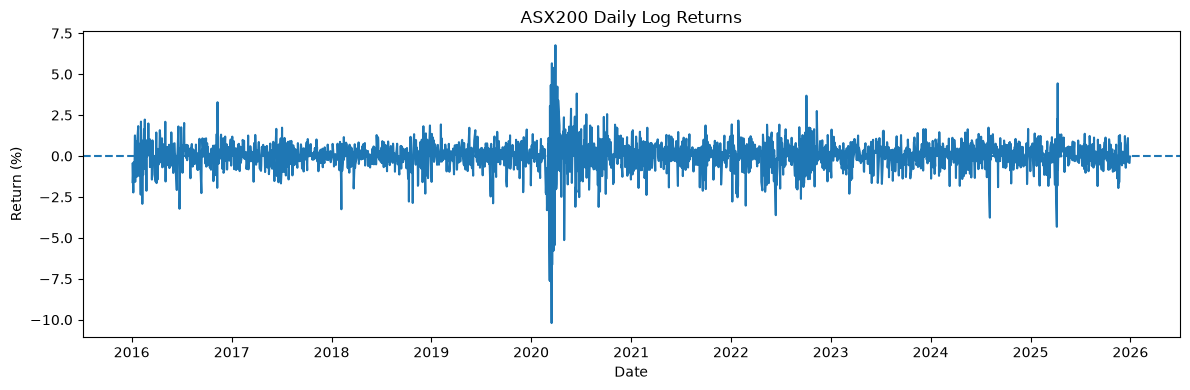

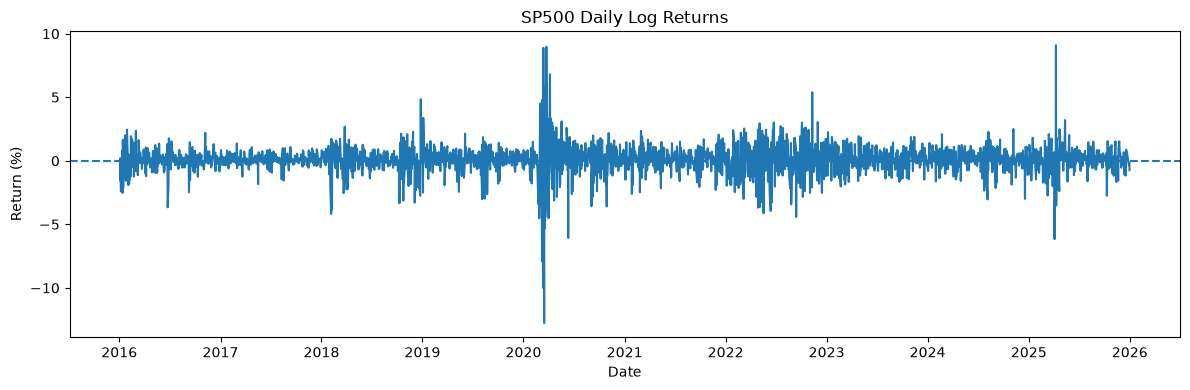

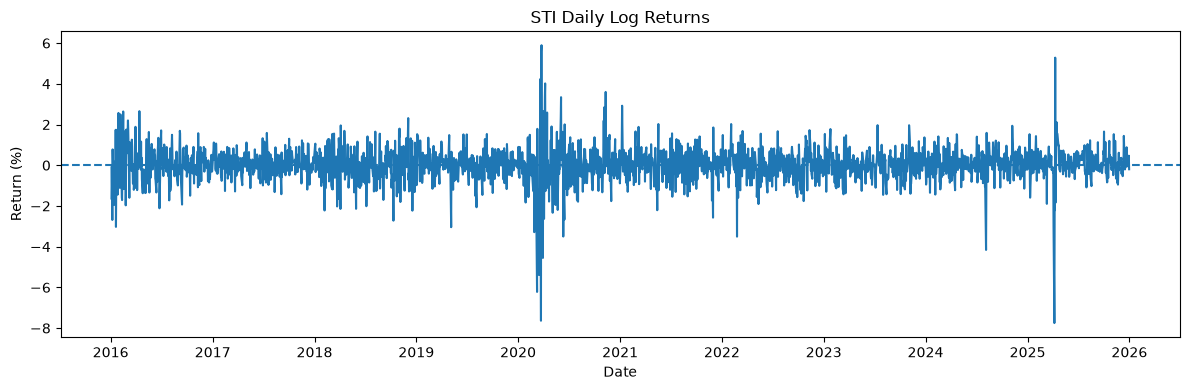

In [9]:
for name, df in markets.items():

    plt.figure(figsize=(12, 4))

    plt.plot(
        df["Date"],
        df["Market_Return"]
    )

    plt.axhline(0, linestyle="--")

    plt.title(f"{name} Daily Log Returns")
    plt.xlabel("Date")
    plt.ylabel("Return (%)")

    plt.tight_layout()
    plt.show()